In [9]:
import tensorflow as tf
from tensorflow import keras
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
train_dir = "D:\Artificial Intelligence\Deep Learning\Data\Icream_pizza\Train"
test_dir = "D:\Artificial Intelligence\Deep Learning\Data\Icream_pizza\Test"

img_size = (224, 224)
batch_size = 32

<>:1: SyntaxWarning: invalid escape sequence '\A'
<>:2: SyntaxWarning: invalid escape sequence '\A'
<>:1: SyntaxWarning: invalid escape sequence '\A'
<>:2: SyntaxWarning: invalid escape sequence '\A'
C:\Users\HASEEB\AppData\Local\Temp\ipykernel_828\4276505104.py:1: SyntaxWarning: invalid escape sequence '\A'
  train_dir = "D:\Artificial Intelligence\Deep Learning\Data\Icream_pizza\Train"
C:\Users\HASEEB\AppData\Local\Temp\ipykernel_828\4276505104.py:2: SyntaxWarning: invalid escape sequence '\A'
  test_dir = "D:\Artificial Intelligence\Deep Learning\Data\Icream_pizza\Test"


In [11]:
train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    validation_split = 0.2,
    rotation_range = 20,
    zoom_range = 0.2,
    horizontal_flip = True
)
test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

In [12]:
train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size = img_size,
    batch_size = batch_size,
    class_mode = 'binary',  
    subset = 'training'
)
val_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    subset='validation'
)

test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    shuffle=False   
)

Found 575 images belonging to 2 classes.
Found 143 images belonging to 2 classes.


Found 106 images belonging to 2 classes.


In [13]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping

In [14]:
base_model = MobileNetV2(
    input_shape=(224,224, 3),
    include_top=False,    
    weights='imagenet'
)
base_model.trainable = False
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')   # FIXED
])


In [16]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',      # FIXED
    metrics=['accuracy']
)


early_stop = EarlyStopping(
    patience=3,
    restore_best_weights=True
)


history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    callbacks=[early_stop]
)

Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 52s 2s/step - accuracy: 0.5443 - loss: 59.0541 - val_accuracy: 0.5455 - val_loss: 36.5040
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.5443 - loss: 20.0196 - val_accuracy: 0.5455 - val_loss: 4.6326
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.5496 - loss: 1.1912 - val_accuracy: 0.5874 - val_loss: 0.6802
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.7287 - loss: 0.6790 - val_accuracy: 0.7692 - val_loss: 0.6706
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.6957 - loss: 0.6554 - val_accuracy: 0.6294 - val_loss: 0.6356
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.6070 - loss: 0.6171 - val_accuracy: 0.6154 - val_loss: 0.5992
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 15s 848ms/step - accuracy: 0.6417 - loss: 0.5831 - val_accuracy: 0.6713 - val_loss: 0.5619
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 16s 882ms/step - accuracy: 0.7043 - loss: 0.5411 - val_accuracy: 0.7273 - 

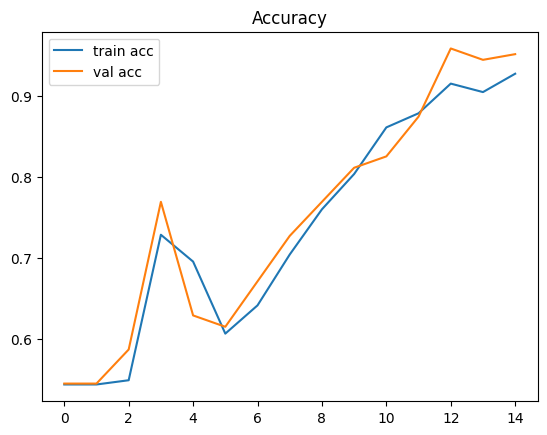

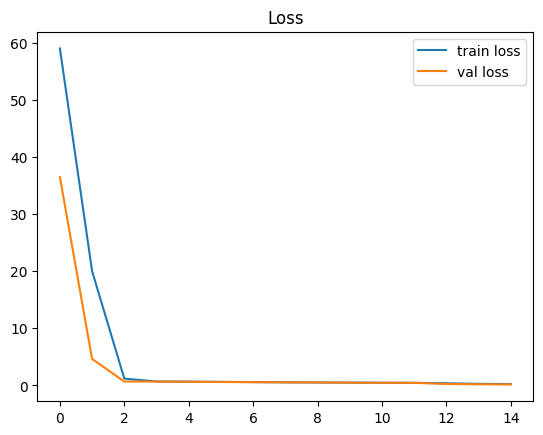

In [17]:
plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.legend()
plt.title("Accuracy")
plt.show()


plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.title("Loss")
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 447ms/step - accuracy: 0.9906 - loss: 0.1002
Test Accuracy: 0.9905660152435303
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


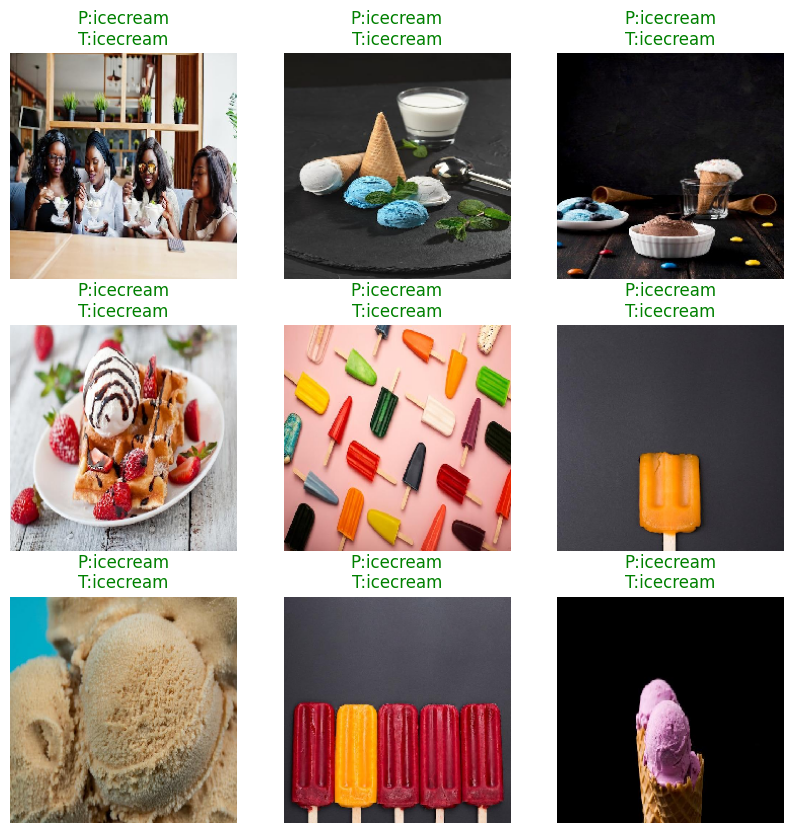

In [19]:
loss, acc = model.evaluate(test_data)
print("Test Accuracy:", acc)
class_names = list(train_data.class_indices.keys())
images, labels = next(test_data)
preds = model.predict(images)
plt.figure(figsize=(10,10))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i])
    pred_label = class_names[np.argmax(preds[i])]
    true_label = class_names[np.argmax(labels[i])]
    color = "green" if pred_label == true_label else "red"
    plt.title(f"P:{pred_label}\nT:{true_label}", color=color)
    plt.axis("off")

plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 346ms/step - accuracy: 0.9906 - loss: 0.1002
Test Accuracy: 0.9905660152435303
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 463ms/step


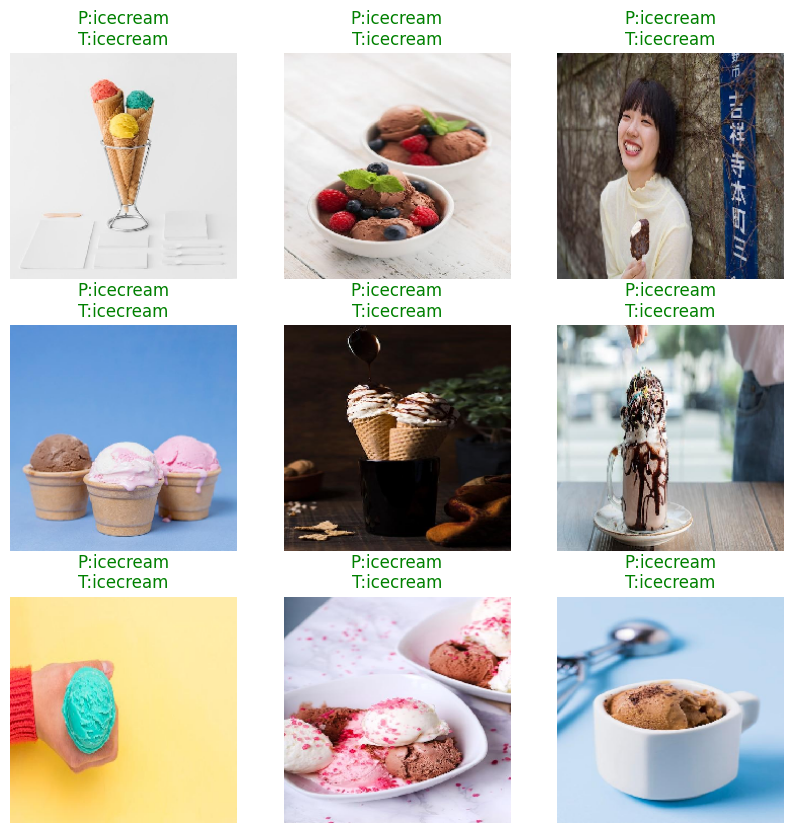

In [20]:
loss, acc = model.evaluate(test_data)
print("Test Accuracy:", acc)
class_names = list(train_data.class_indices.keys())
images, labels = next(test_data)
preds = model.predict(images)
plt.figure(figsize=(10,10))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i])
    pred_label = class_names[np.argmax(preds[i])]
    true_label = class_names[np.argmax(labels[i])]
    color = "green" if pred_label == true_label else "red"
    plt.title(f"P:{pred_label}\nT:{true_label}", color=color)
    plt.axis("off")

plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 370ms/step - accuracy: 0.9906 - loss: 0.1002
Test Accuracy: 0.9905660152435303
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step


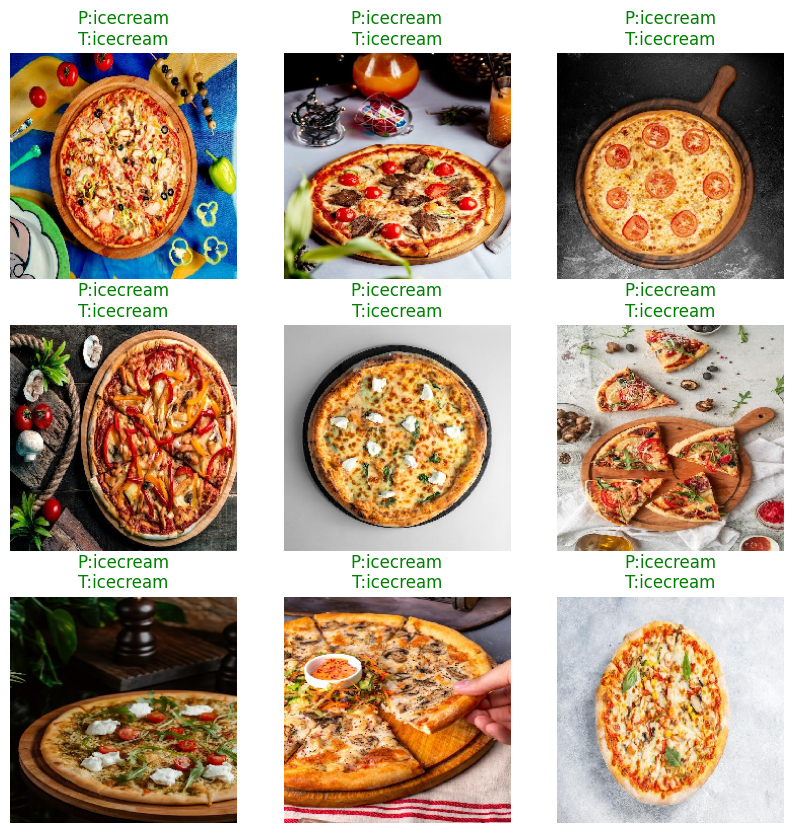

In [21]:
loss, acc = model.evaluate(test_data)
print("Test Accuracy:", acc)
class_names = list(train_data.class_indices.keys())
images, labels = next(test_data)
preds = model.predict(images)
plt.figure(figsize=(10,10))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i])
    pred_label = class_names[np.argmax(preds[i])]
    true_label = class_names[np.argmax(labels[i])]
    color = "green" if pred_label == true_label else "red"
    plt.title(f"P:{pred_label}\nT:{true_label}", color=color)
    plt.axis("off")

plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 311ms/step - accuracy: 0.9906 - loss: 0.1002
Test Accuracy: 0.9905660152435303
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


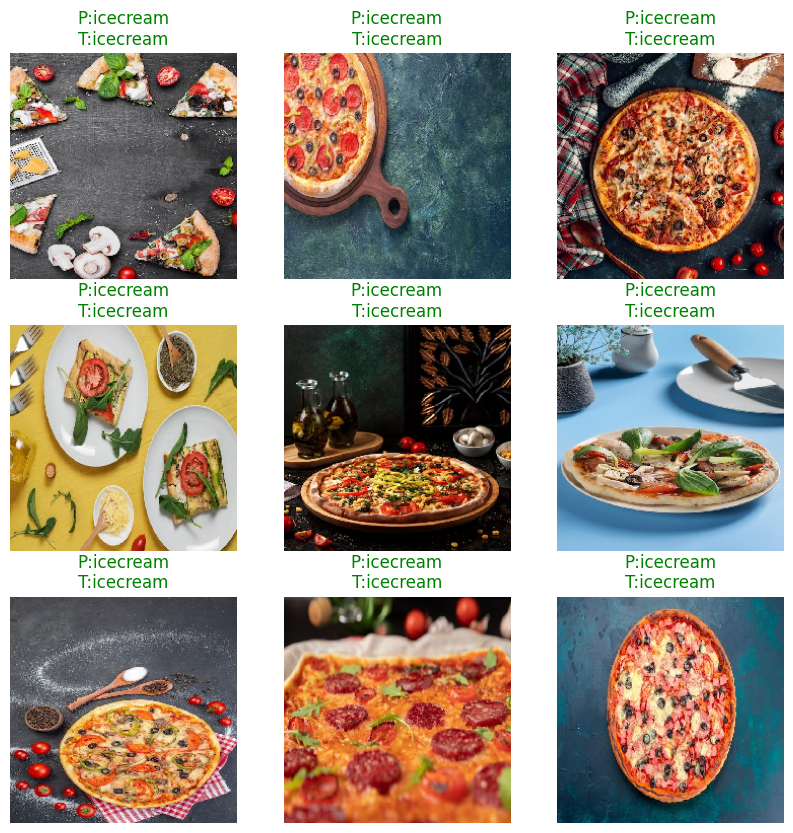

In [22]:
loss, acc = model.evaluate(test_data)
print("Test Accuracy:", acc)
class_names = list(train_data.class_indices.keys())
images, labels = next(test_data)
preds = model.predict(images)
plt.figure(figsize=(10,10))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i])
    pred_label = class_names[np.argmax(preds[i])]
    true_label = class_names[np.argmax(labels[i])]
    color = "green" if pred_label == true_label else "red"
    plt.title(f"P:{pred_label}\nT:{true_label}", color=color)
    plt.axis("off")

plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 332ms/step - accuracy: 0.9906 - loss: 0.1002
Test Accuracy: 0.9905660152435303
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 419ms/step


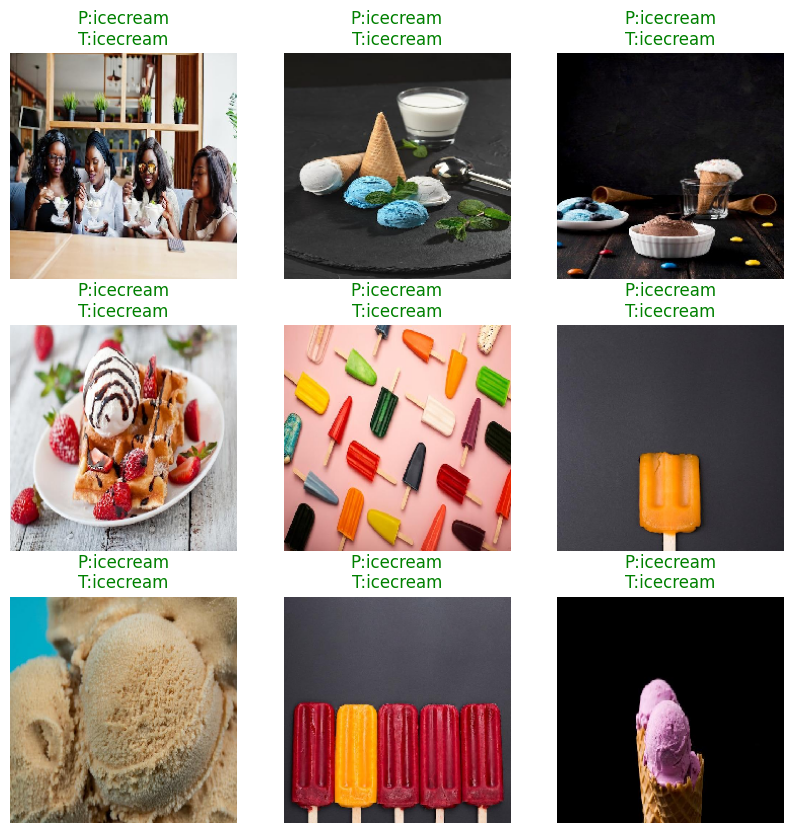

In [23]:
loss, acc = model.evaluate(test_data)
print("Test Accuracy:", acc)
class_names = list(train_data.class_indices.keys())
images, labels = next(test_data)
preds = model.predict(images)
plt.figure(figsize=(10,10))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i])
    pred_label = class_names[np.argmax(preds[i])]
    true_label = class_names[np.argmax(labels[i])]
    color = "green" if pred_label == true_label else "red"
    plt.title(f"P:{pred_label}\nT:{true_label}", color=color)
    plt.axis("off")

plt.show()